In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

COLOR_ZPDES = "#114B5B"
COLOR_BASELINE = "#9CC19F"

sims = pd.read_csv('psychometrics/sims_v3_prolific/sims_all.csv')
sims = sims.pivot(index=['id_participant', 'condition'], columns='session_id', values='SDI')
sims = sims.reset_index()
sims = sims.rename({'id_participant': 'participant_id', 1: 's_0', 4: 's_1', 5: 's_2', 8: 's_3'}, axis=1)

nasa = pd.read_csv('psychometrics/nasa_tlx_v3_prolific/nasa_tlx_all.csv')
nasa = nasa.pivot(index=['id_participant', 'condition'], columns='session_id', values='load_index')
nasa = nasa.reset_index()
nasa = nasa.rename({'id_participant': 'participant_id', 1: 's_0', 4: 's_1', 5: 's_2', 8: 's_3'}, axis=1)

intra = pd.read_csv('../outputs/v3_prolific/v3_prolific_F1_intra.csv')

# Merge the dataframes on participant_id and condition to align the corresponding sessions
sims_intra = pd.merge(sims, intra, on=['participant_id', 'condition'], suffixes=('_sims', '_intra'))
nasa_intra = pd.merge(nasa, intra, on=['participant_id', 'condition'], suffixes=('_nasa', '_intra'))
sims_nasa = pd.merge(sims, nasa, on=['participant_id', 'condition'], suffixes=('_sims', '_nasa'))

In [24]:
def get_correl(df, DV1, DV2, default_color='blue'):
    fig, axs = plt.subplots(2, 2)
    for i, ax in enumerate(axs.flatten()):
        # Plot the session data
        ax.plot(df[f's_{i}_{DV1}'], df[f's_{i}_{DV2}'], 'o', linestyle='None', color=default_color)
        pearson_corr = pearsonr(df[f's_{i}_{DV1}'], df[f's_{i}_{DV2}'])
        spearman_corr = spearmanr(df[f's_{i}_{DV1}'], df[f's_{i}_{DV2}'])
        title = f'Session {i}, Pearson={pearson_corr[0]:.2f},\n Spearman={spearman_corr[0]:.2f}'
        if pearson_corr[1] < 0.05:
            title += '*'
        if spearman_corr[1] < 0.05:
            title += '*'
        ax.set_title(title)
        ax.set_xlabel(DV1)
        ax.set_ylabel(DV2)
    plt.tight_layout()

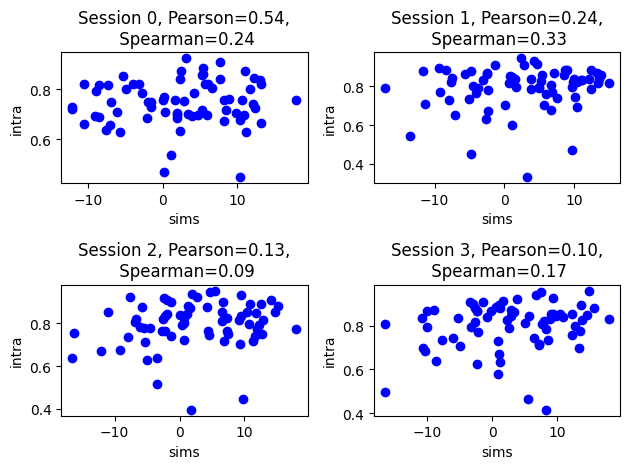

In [25]:
get_correl(sims_intra, 'sims', 'intra')

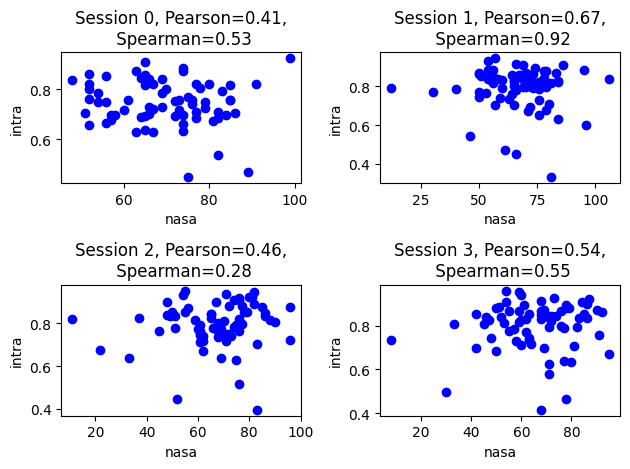

In [26]:
get_correl(nasa_intra, 'nasa', 'intra')

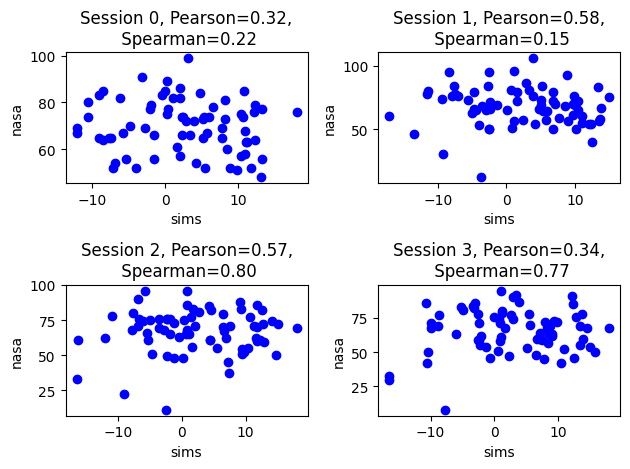

In [27]:
get_correl(sims_nasa, 'sims', 'nasa')

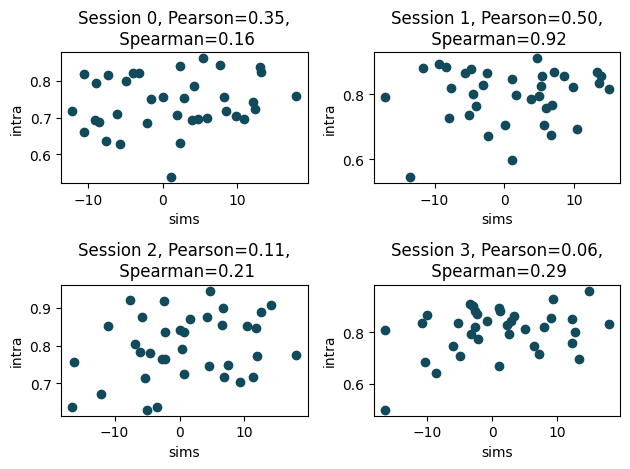

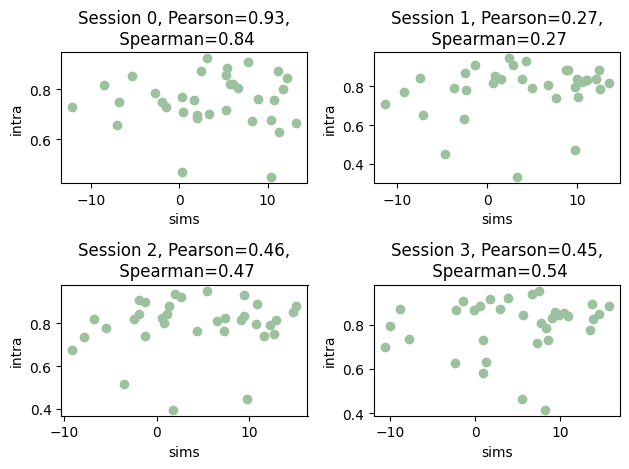

In [28]:
get_correl(sims_intra[sims_intra['condition']=='zpdes'], 'sims', 'intra', default_color=COLOR_ZPDES)
get_correl(sims_intra[sims_intra['condition']=='baseline'], 'sims', 'intra', default_color=COLOR_BASELINE)

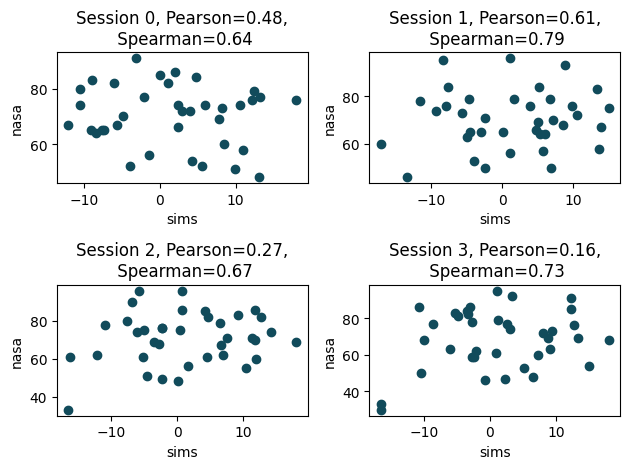

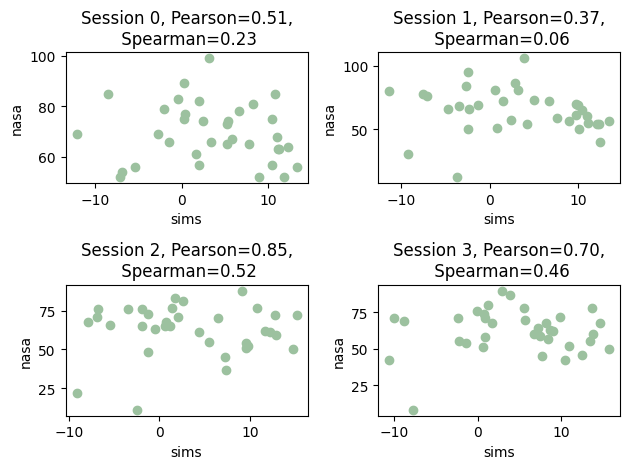

In [29]:
get_correl(sims_nasa[sims_nasa['condition']=='zpdes'], 'sims', 'nasa', default_color=COLOR_ZPDES)
get_correl(sims_nasa[sims_nasa['condition']=='baseline'], 'sims', 'nasa', default_color=COLOR_BASELINE)

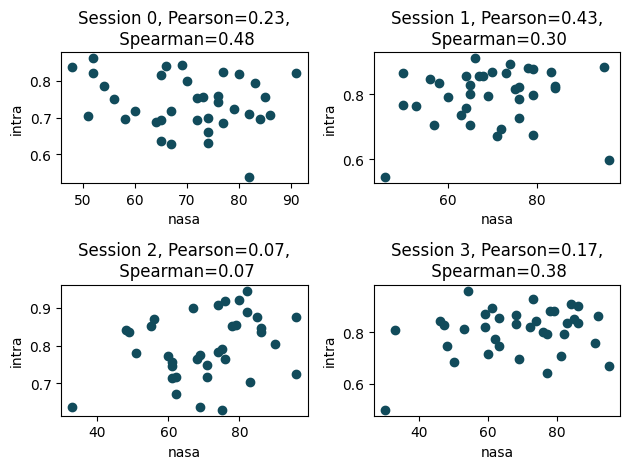

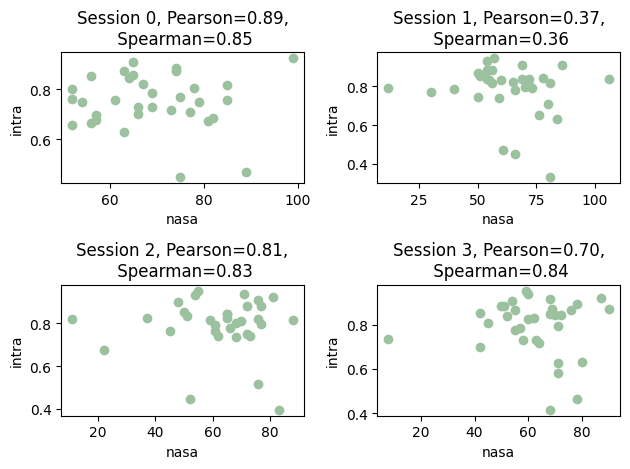

In [30]:
get_correl(nasa_intra[nasa_intra['condition']=='zpdes'], 'nasa', 'intra', default_color=COLOR_ZPDES)
get_correl(nasa_intra[nasa_intra['condition']=='baseline'], 'nasa', 'intra', default_color=COLOR_BASELINE)